# SaaS Financial Benchmark and Revenue Outlook
**Salesforce (CRM), Shopify (SHOP), Atlassian (TEAM) and ServiceNow (NOW)**

Python, pandas and scikit-learn | Data: Yahoo Finance annual financial statements

## Summary

**Question.** Which of these four SaaS companies combines the best growth with the best operating efficiency, and what could their revenue look like by 2028?

**Method.** Annual revenue and operating income were collected, put on a comparable fiscal-year basis, compared on size, 3-year growth (CAGR) and operating margin, and projected to 2028 with two simple methods that were backtested on 2025.

**Key findings**
- **Size:** Salesforce is the largest company by far: $41.5B in its latest fiscal year, about 3.1x ServiceNow and 1.4x the other three combined.
- **Growth:** Shopify (27.3%), Atlassian (23.1%) and ServiceNow (22.4%) grew 2.3 to 2.8 times faster than Salesforce (9.8%).
- **Profitability:** Salesforce has the highest operating margin (20.2%), followed by Shopify (16.3%) and ServiceNow (13.7%). Atlassian is slightly negative (-2.5%).
- **Best combination:** Shopify leads the three higher-growth companies on both growth and margin.
- **Projection risk:** for Shopify, Atlassian and ServiceNow, the choice of projection method changes the 2028 estimate by 27% to 39%, more than the +/-15% scenarios do.

**Main limitations:** only four annual data points per company, fiscal years that do not end on the same date, and operating income for a single year. Details at the end.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

USE_LIVE_DATA = False   # True = download from Yahoo Finance (needs internet and `pip install yfinance`)
TICKERS = ["CRM", "SHOP", "TEAM", "NOW"]
COLORS = {"CRM": "#1f77b4", "SHOP": "#2ca02c", "TEAM": "#ff7f0e", "NOW": "#9467bd"}

The notebook runs on a **snapshot** of annual statements (in $B) taken from Yahoo Finance, so results are reproducible without internet access. Set `USE_LIVE_DATA = True` to download fresh data with `yfinance`; the live path was not run for this version, so check it before relying on it. The table below shows each company's latest fiscal year end in the snapshot.

In [2]:
def to_series(d):
    return pd.Series(list(d.values()), index=pd.to_datetime(list(d.keys())), dtype=float)

if USE_LIVE_DATA:
    import yfinance as yf
    fin = {t: yf.Ticker(t).financials for t in TICKERS}
    revenue_raw = {t: fin[t].loc["Total Revenue"].sort_index() / 1e9 for t in TICKERS}
    op_income_raw = {t: fin[t].loc["Operating Income"].dropna().sort_index() / 1e9 for t in TICKERS}
else:
    # Snapshot of Yahoo Finance annual statements, in $B. Index = fiscal year-end date.
    revenue_raw = {
        "CRM":  to_series({"2023-01-31": 31.35, "2024-01-31": 34.86, "2025-01-31": 37.90, "2026-01-31": 41.52}),
        "SHOP": to_series({"2022-12-31": 5.60, "2023-12-31": 7.06, "2024-12-31": 8.88, "2025-12-31": 11.56}),
        "TEAM": to_series({"2022-06-30": 2.80, "2023-06-30": 3.53, "2024-06-30": 4.36, "2025-06-30": 5.22}),
        "NOW":  to_series({"2022-12-31": 7.24, "2023-12-31": 8.97, "2024-12-31": 10.98, "2025-12-31": 13.28}),
    }
    op_income_raw = {
        "CRM":  to_series({"2025-01-31": 7.67}),
        "SHOP": to_series({"2025-12-31": 1.88}),
        "TEAM": to_series({"2025-06-30": -0.13}),
        "NOW":  to_series({"2025-12-31": 1.82}),
    }

pd.DataFrame({
    "Latest fiscal year end": {t: s.index.max().date() for t, s in revenue_raw.items()},
    "Latest revenue ($B)": {t: s.iloc[-1] for t, s in revenue_raw.items()},
})

,Latest fiscal year end,Latest revenue ($B)
CRM,2026-01-31,41.52
SHOP,2025-12-31,11.56
TEAM,2025-06-30,5.22
NOW,2025-12-31,13.28


## 2. Data preparation

All four companies are put on the same footing before comparing them. Salesforce (CRM) ends its fiscal year in January, so a year ending Jan-2026 is labelled **2025** (11 of its 12 months fall in calendar 2025). Atlassian (TEAM) ends in June and is kept on its own fiscal-year label, so its 2025 is about six months earlier than the Dec-2025 reports of SHOP and NOW.

In [3]:
def reporting_year(period_end):
    """Calendar year in which most of the fiscal year falls (a January year-end belongs to the previous year)."""
    return period_end.year - 1 if period_end.month == 1 else period_end.year

revenue = pd.DataFrame({
    t: pd.Series(s.values, index=[reporting_year(d) for d in s.index])
    for t, s in revenue_raw.items()
}).sort_index().loc[2022:2025]

assert revenue.notna().all().all(), "Missing revenue values"
assert list(revenue.index) == [2022, 2023, 2024, 2025]
revenue.round(2)

,CRM,SHOP,TEAM,NOW
2022,31.35,5.60,2.80,7.24
2023,34.86,7.06,3.53,8.97
2024,37.90,8.88,4.36,10.98
2025,41.52,11.56,5.22,13.28


## 3. Size and trajectory

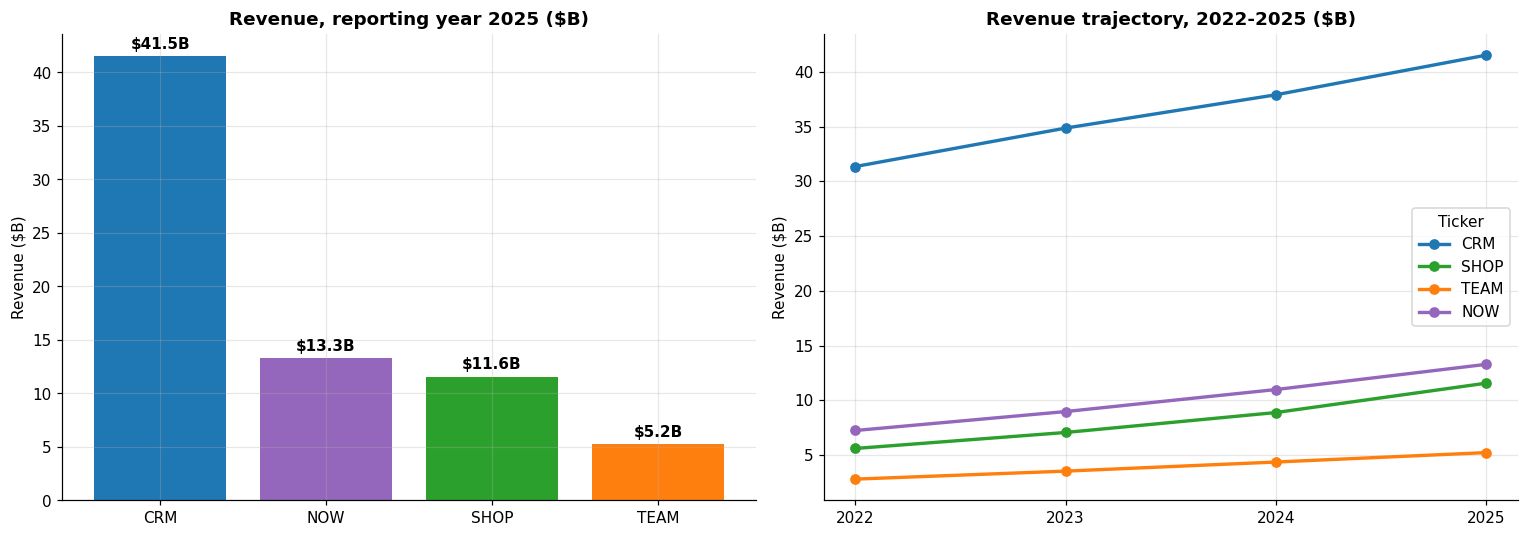

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rev_2025 = revenue.loc[2025].sort_values(ascending=False)
bars = axes[0].bar(rev_2025.index, rev_2025.values, color=[COLORS[t] for t in rev_2025.index])
axes[0].bar_label(bars, labels=[f"${v:.1f}B" for v in rev_2025.values], padding=3, fontweight="bold")
axes[0].set_title("Revenue, reporting year 2025 ($B)", fontweight="bold")
axes[0].set_ylabel("Revenue ($B)")

for t in TICKERS:
    axes[1].plot(revenue.index, revenue[t], marker="o", linewidth=2.2, color=COLORS[t], label=t)
axes[1].set_title("Revenue trajectory, 2022-2025 ($B)", fontweight="bold")
axes[1].set_ylabel("Revenue ($B)")
axes[1].set_xticks(revenue.index)
axes[1].legend(title="Ticker")

plt.tight_layout()
plt.show()

## 4. Growth and profitability

Revenue CAGR compares 3-year growth rates (2022 to 2025). Operating margin uses the latest fiscal year in the snapshot for each company; the fiscal year end is shown so the periods are transparent.

In [5]:
cagr = (revenue.loc[2025] / revenue.loc[2022]) ** (1 / 3) - 1   # 3 yearly steps: 2022 -> 2025

latest_fy = {t: op_income_raw[t].index.max() for t in TICKERS}
profit = pd.DataFrame({
    "Fiscal year end": [latest_fy[t].date() for t in TICKERS],
    "Revenue ($B)": [revenue_raw[t][latest_fy[t]] for t in TICKERS],
    "Operating income ($B)": [op_income_raw[t][latest_fy[t]] for t in TICKERS],
}, index=TICKERS)
profit["Operating margin (%)"] = (profit["Operating income ($B)"] / profit["Revenue ($B)"] * 100).round(1)

summary = pd.DataFrame({
    "Revenue 2025 ($B)": revenue.loc[2025],
    "Revenue CAGR 2022-25 (%)": (cagr * 100).round(1),
    "Operating margin (%)": profit["Operating margin (%)"],
}).sort_values("Revenue CAGR 2022-25 (%)", ascending=False)
summary

,Revenue 2025 ($B),Revenue CAGR 2022-25 (%),Operating margin (%)
SHOP,11.56,27.3,16.3
TEAM,5.22,23.1,-2.5
NOW,13.28,22.4,13.7
CRM,41.52,9.8,20.2


In [6]:
profit

,Fiscal year end,Revenue ($B),Operating income ($B),Operating margin (%)
CRM,2025-01-31,37.90,7.67,20.2
SHOP,2025-12-31,11.56,1.88,16.3
TEAM,2025-06-30,5.22,-0.13,-2.5
NOW,2025-12-31,13.28,1.82,13.7


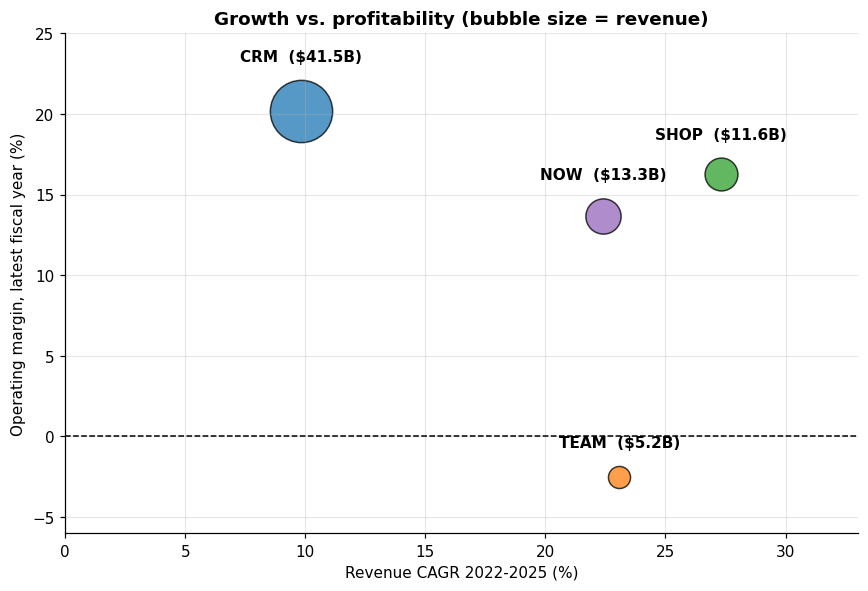

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for t in TICKERS:
    size = revenue.loc[2025, t] * 40
    ax.scatter(cagr[t] * 100, profit.loc[t, "Operating margin (%)"], s=size,
               color=COLORS[t], alpha=0.75, edgecolor="black")
    ax.annotate(f"{t}  (${revenue.loc[2025, t]:.1f}B)", (cagr[t] * 100, profit.loc[t, "Operating margin (%)"]),
                xytext=(0, 12 + size ** 0.5 / 2), textcoords="offset points", ha="center", fontweight="bold")
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_xlabel("Revenue CAGR 2022-2025 (%)")
ax.set_ylabel("Operating margin, latest fiscal year (%)")
ax.set_title("Growth vs. profitability (bubble size = revenue)", fontweight="bold")
ax.set_xlim(0, 33)
ax.set_ylim(-6, 25)
plt.tight_layout()
plt.show()

## 5. Revenue projections to 2028

Two simple methods are compared: a **linear trend** (ordinary least squares on 2022-2025) and a **growth-rate extrapolation** (2025 revenue grown at each company's historical CAGR).

In [8]:
years = np.array([2022, 2023, 2024, 2025])
future = np.array([2026, 2027, 2028])

linear = pd.DataFrame(index=future, columns=TICKERS, dtype=float)
r2 = {}
for t in TICKERS:
    model = LinearRegression().fit(years.reshape(-1, 1), revenue[t].values)
    linear[t] = model.predict(future.reshape(-1, 1))
    r2[t] = model.score(years.reshape(-1, 1), revenue[t].values)

growth_based = pd.DataFrame(
    {t: [revenue.loc[2025, t] * (1 + cagr[t]) ** k for k in (1, 2, 3)] for t in TICKERS}, index=future
)

forecast_2028 = pd.DataFrame({
    "Linear trend 2028 ($B)": linear.loc[2028],
    "Growth-rate extrapolation 2028 ($B)": growth_based.loc[2028],
}).round(2)
forecast_2028["Gap (%)"] = ((forecast_2028.iloc[:, 1] / forecast_2028.iloc[:, 0] - 1) * 100).round(0)
forecast_2028

,Linear trend 2028 ($B),Growth-rate extrapolation 2028 ($B),Gap (%)
CRM,51.51,54.99,7.0
SHOP,17.14,23.86,39.0
TEAM,7.62,9.73,28.0
NOW,19.18,24.36,27.0


**Backtest.** Both methods are fitted on 2022-2024 only and used to predict 2025 (held out). The project target was a MAPE below 10%.

In [9]:
def mape(pred, actual):
    return abs(pred - actual) / actual * 100

rows = {}
for t in TICKERS:
    train = revenue.loc[2022:2024, t]                      # fit on 2022-2024 only
    actual = revenue.loc[2025, t]                          # hold out 2025
    lin_pred = LinearRegression().fit(train.index.values.reshape(-1, 1), train.values).predict([[2025]])[0]
    g = (train[2024] / train[2022]) ** 0.5 - 1
    rows[t] = {"Linear trend MAPE (%)": mape(lin_pred, actual),
               "Growth-rate MAPE (%)": mape(train[2024] * (1 + g), actual)}

backtest = pd.DataFrame(rows).T
backtest.loc["Average"] = backtest.mean()
backtest.round(1)

,Linear trend MAPE (%),Growth-rate MAPE (%)
CRM,0.6,0.4
SHOP,9.5,3.3
TEAM,1.9,4.2
NOW,3.6,1.8
Average,3.9,2.4


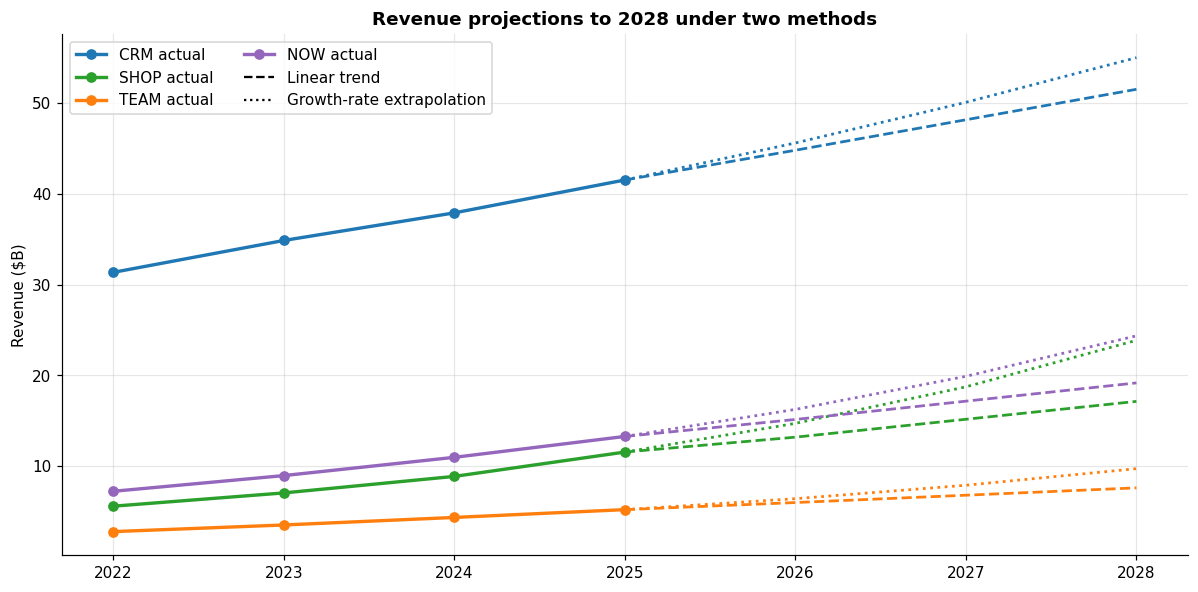

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for t in TICKERS:
    ax.plot(revenue.index, revenue[t], marker="o", linewidth=2.2, color=COLORS[t], label=f"{t} actual")
    ax.plot([2025, *future], [revenue.loc[2025, t], *linear[t]], linestyle="--", color=COLORS[t], linewidth=1.8)
    ax.plot([2025, *future], [revenue.loc[2025, t], *growth_based[t]], linestyle=":", color=COLORS[t], linewidth=1.8)
ax.plot([], [], "k--", label="Linear trend")
ax.plot([], [], "k:", label="Growth-rate extrapolation")
ax.set_xticks([2022, 2023, 2024, 2025, 2026, 2027, 2028])
ax.set_ylabel("Revenue ($B)")
ax.set_title("Revenue projections to 2028 under two methods", fontweight="bold")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 6. Scenarios for 2028

Bear and bull cases apply a uniform -15% / +15% to the linear-trend base. The growth-rate extrapolation is shown next to them as a reference.

In [11]:
base_2028 = linear.loc[2028]
scenarios = pd.DataFrame({
    "Bear (-15%)": base_2028 * 0.85,
    "Base (linear trend)": base_2028,
    "Bull (+15%)": base_2028 * 1.15,
    "Growth-rate extrapolation": growth_based.loc[2028],
}).round(2)
scenarios.sort_values("Base (linear trend)", ascending=False)

,Bear (-15%),Base (linear trend),Bull (+15%),Growth-rate extrapolation
CRM,43.78,51.51,59.23,54.99
NOW,16.30,19.18,22.05,24.36
SHOP,14.57,17.14,19.71,23.86
TEAM,6.48,7.62,8.76,9.73


## 7. Dashboard

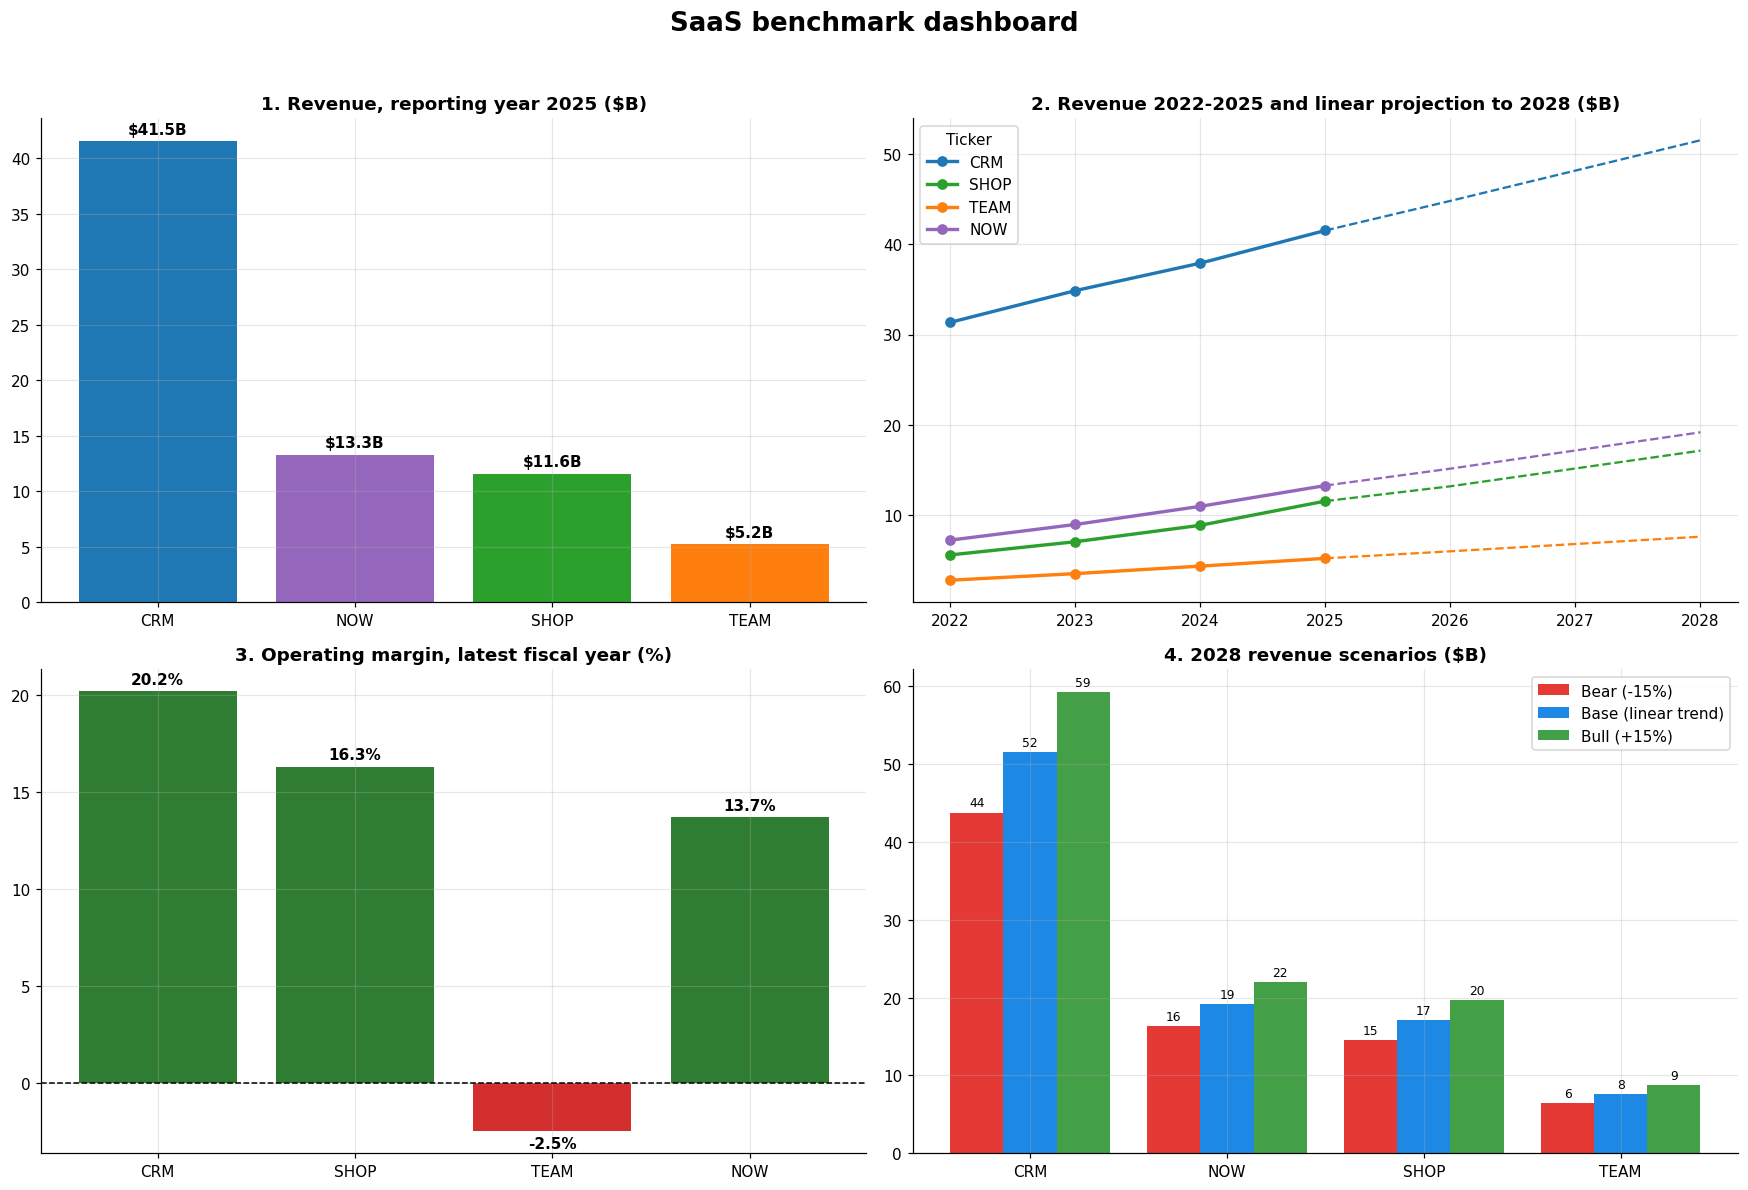

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("SaaS benchmark dashboard", fontsize=17, fontweight="bold")

# 1. Size
order = rev_2025.index
b = axes[0, 0].bar(order, rev_2025.values, color=[COLORS[t] for t in order])
axes[0, 0].bar_label(b, labels=[f"${v:.1f}B" for v in rev_2025.values], padding=3, fontweight="bold")
axes[0, 0].set_title("1. Revenue, reporting year 2025 ($B)", fontweight="bold")

# 2. Trajectory and linear projection
for t in TICKERS:
    axes[0, 1].plot(revenue.index, revenue[t], marker="o", linewidth=2.2, color=COLORS[t], label=t)
    axes[0, 1].plot([2025, *future], [revenue.loc[2025, t], *linear[t]], linestyle="--", color=COLORS[t])
axes[0, 1].set_title("2. Revenue 2022-2025 and linear projection to 2028 ($B)", fontweight="bold")
axes[0, 1].set_xticks([2022, 2023, 2024, 2025, 2026, 2027, 2028])
axes[0, 1].legend(title="Ticker")

# 3. Operating margin
m = profit["Operating margin (%)"]
b = axes[1, 0].bar(m.index, m.values, color=["#2e7d32" if v > 0 else "#d32f2f" for v in m.values])
axes[1, 0].bar_label(b, labels=[f"{v:.1f}%" for v in m.values], padding=3, fontweight="bold")
axes[1, 0].axhline(0, color="black", linewidth=1, linestyle="--")
axes[1, 0].set_title("3. Operating margin, latest fiscal year (%)", fontweight="bold")

# 4. Scenarios 2028
sc = scenarios.sort_values("Base (linear trend)", ascending=False)[["Bear (-15%)", "Base (linear trend)", "Bull (+15%)"]]
x = np.arange(len(sc)); w = 0.27
for i, (col, color) in enumerate(zip(sc.columns, ["#e53935", "#1e88e5", "#43a047"])):
    bars = axes[1, 1].bar(x + (i - 1) * w, sc[col], w, label=col, color=color)
    axes[1, 1].bar_label(bars, labels=[f"{v:.0f}" for v in sc[col]], padding=2, fontsize=8)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(sc.index)
axes[1, 1].set_title("4. 2028 revenue scenarios ($B)", fontweight="bold")
axes[1, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 8. Conclusions

### What the data shows
1. **Size.** Salesforce is the market-size leader: $41.5B in the fiscal year ended Jan-2026 ($37.9B the year before). Even on the earlier figure it is more than 2.8x ServiceNow ($13.28B), so the conclusion does not depend on the fiscal-year label. Shopify ($11.56B) and Atlassian ($5.22B) follow.
2. **Growth.** 2022-2025 revenue CAGR: Shopify 27.3%, Atlassian 23.1%, ServiceNow 22.4%, Salesforce 9.8%. Atlassian is the smallest company in dollars but grows about as fast as ServiceNow.
3. **Profitability.** Operating margin in the latest fiscal year: Salesforce 20.2% (year ended Jan-2025), Shopify 16.3%, ServiceNow 13.7%, Atlassian -2.5% (year ended Jun-2025).
4. **Projection accuracy.** Predicting 2025 from 2022-2024, the average error was 2.4% for the growth-rate method and 3.9% for the linear trend, and every company was under the 10% target with both methods. The largest single miss was the linear trend on SHOP (9.5%).
5. **Scenarios.** The two projection methods differ by only 7% for Salesforce, so a +/-15% range covers it. For Shopify, Atlassian and ServiceNow they differ by 27% to 39%, more than the scenario range. Example: Shopify 2028 revenue is $17.1B under the linear trend and $23.9B under growth-rate extrapolation.

### Recommendations
1. **Growth with profitability: Shopify.** It combines the highest growth (27.3%) with a healthy margin (16.3%). ServiceNow is a close second (22.4% growth, 13.7% margin).
2. **Monitor Atlassian rather than judge it.** It grows 23.1% a year with a slightly negative operating margin (-2.5%). Operating income here is as reported by Yahoo Finance, with no adjustment for one-off items or stock-based compensation, so the negative margin is a reason to look at cash flow and next reports, not a verdict.
3. **Salesforce as the stable anchor.** The largest and most profitable of the four, but growing at under 10% a year.

### Limitations
- **Few data points.** Four annual observations per company. In-sample R-squared of the linear trend (0.98 to 1.00) is not evidence of future accuracy, and the backtest uses a single held-out year.
- **Fiscal-year differences.** Salesforce ends in January and Atlassian in June, while Shopify and ServiceNow end in December. Growth rates are comparable, but absolute size and margin figures are offset by up to six months for Atlassian.
- **Margin data.** Operating income is available for one fiscal year per company, and Salesforce's is for the year ended Jan-2025, one year earlier than its latest revenue.
- **Scenarios.** The +/-15% range is a uniform stress test, not a company-specific risk estimate, so it does not show which company is more exposed to the economic cycle.
- **Not covered.** Cash flow, valuation, segment data and quarterly trends.

### Next steps
Add cash flow and free-cash-flow margin, extend the history with quarterly data, and replace the uniform scenario range with company-specific ranges based on historical volatility.